In [16]:
#Imporing the necessary python packages
import pandas as pd
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
from scipy.optimize import curve_fit

In [ ]:
#Info
#Edit here for your specific data
csvFile = "Sample data for MASS_Soar.csv" #Directory
final_csv_name = "output.csv" 
rhomin = "RhoMin" #column name for rhomin 
dm1 = "dm1" #column name for delta apparent mag at 1 arcsec 
dm1_err = "dm1_err" #column name for the error on del-mag @ 0.1"
dm015 = "dm015" #column name for delta apparent mag at 0.15 arcsec
dm015_err = "dm015_err" #column name for the error on del-mag @ 0.15"
plx = "Plx" #column name for plx  
plx_err = "err_plx" #column name for the error on distance (in arcsec)
cMag = "V" #column name for combined magnitude
cMag_err = "err_CMag" #column name for the error on combined magnitude 
colormap = "viridis" #name of the colormap you'd like to use

cMag_VBand = True #Is the combined magnitude in V-band? (false is I-band)
dm_VBand = False #Is delta magnitude in V-band? (false is I-band)
cMag_Abs = False #Is ccombined magnitude in absolute mag?
dm_Abs = False #is delta magnitude in absolute mag? 
plx_arcsec = True #is plx in arcsec? (false is milliarcsecond)
remove_bad_points = True #Removes impossible data / data that doesn't fit within MLR

In [ ]:
#Important Functions
def getIndMags(delMag, cMag, delMag_err, cMag_err):
    """Takes the magnitude difference between star 1 & 2 (delMag) and the combined magnitude to find individual magnitudes"""
    m1 = (2.5 * np.log10(1 + 10**(-0.4*delMag))) + cMag
    m1_err = np.sqrt(((10**(-0.4*delMag) * delMag_err) / ( 1 + 10**(-0.4*delMag)))**2 + (cMag_err)**2)
    m2 = m1 + delMag
    m2_err = np.sqrt(((delMag_err) / (1+10**(-0.4*delMag)))**2 + (cMag_err)**2)
    return m1, m2, m1_err, m2_err

def getAbsMag(appMag, d, mag_err, d_err):
    """Takes in an apparent magnitude (appMag) and distance in PC (d) to return the absolute magnitude"""
    M = appMag - (5 * np.log10(d)) +5
    M_err = np.sqrt( (mag_err**2) + ((5 * d_err) / (d * np.log(10) ))**2 )
    return M, M_err

def toVBand(mag, mag_err):
    """Converts I-band magnitudes into V-band magnitudes using a linear curve fit"""
    c0 = 1.342419195727928
    c1 = -0.6388236738633501
    v = (c0*mag) + c1
    v_err = np.abs(c0 * mag_err)
    return v, v_err

def getMass(V, V_err):
    """Takes an absolute V-band magnitude (Mv) and uses the MLR from 'The Solar Neighborhood' paper to return an object's mass in Msun. 
    This relation does not work for magnitudes > 19"""
    c0 = 0.19226
    c0_err = 0.000424
    c1 = -0.050737
    c1_err = 0.000582
    c2 = 0.010137
    c2_err = 0.00021
    c3 = -0.00075399
    c3_err = 0.0000457
    c4 = -1.9858e-05
    c4_err = 0.0000109
    x_0 = 13.0
    mass = c0 + c1*(V - x_0) + c2*((V - x_0)**2) + c3*((V - x_0)**3) + c4*((V - x_0)**4)
    mass_err = np.sqrt((c1 + (2*c2*(V-x_0)) + (3*c3*(V-x_0)**2) + ((4*c4*(V-x_0)**3) * V_err))**2 + 
                      (1 * c0_err)**2 + ((V-x_0)*c1_err)**2 + (((V-x_0)**2)*c2_err)**2 +
                      (((V-x_0)**3)*c3_err)**2 + (((V-x_0)**4)*c4_err)**2)
    return mass, mass_err

In [ ]:
#Reading in Data 
df = pd.read_csv(csvFile)

#Putting data into numerical values 
df[rhomin] = pd.to_numeric(df[rhomin], errors='coerce')
df[dm015] = pd.to_numeric(df[dm015], errors='coerce')
df[dm1] = pd.to_numeric(df[dm1], errors='coerce')
df[plx] = pd.to_numeric(df[plx], errors='coerce')
df[cMag] = pd.to_numeric(df[cMag], errors='coerce')
df[cMag_err] = pd.to_numeric(df[cMag_err], errors='coerce')
df[dm015_err] = pd.to_numeric(df[dm015_err], errors='coerce')
df[dm1_err] = pd.to_numeric(df[dm1_err], errors='coerce')
df[plx_err] = pd.to_numeric(df[plx_err], errors='coerce')

#Getting distance
if plx_arcsec == False:
    df[plx] = df[plx]/1000
    df[plx_err] = df[plx_err]/1000
df["Dist (PC)"] = 1/df[plx]
df["err_dist"] = (df[plx_err]) * (1 / (df[plx]**2)) #(in pc)

#setting everything into vband
if cMag_VBand == False:
    df[cMag], df[cMag_err] = toVBand(df[cMag], df[cMag_err])
if dm_VBand == False:
    df[dm015], df[dm015_err] = toVBand(df[dm015], df[dm015_err])
    df[dm1], df[dm1_err] = toVBand(df[dm1], df[dm1_err])

#putting everything into absolute mags
if cMag_Abs == False:
    df[cMag], df[cMag_err] = getAbsMag(df[cMag], df["Dist (PC)"], df[cMag_err], df['err_dist'])
if dm_Abs == False:
    df[dm015], df[dm015_err] = getAbsMag(df[dm015], df["Dist (PC)"], df[dm015_err], df['err_dist'])
    df[dm1], df[dm1_err] = getAbsMag(df[dm1], df["Dist (PC)"], df[dm1_err], df['err_dist'])

#getting individual mags (in abs V-band)
df["Mv1_015"], df["Mv2_015"], df["Mv1_015_err"], df["Mv2_015_err"] = getIndMags(df[dm015], df[cMag], df[dm015_err], df[cMag_err])
df["Mv1_1"], df["Mv2_1"], df["Mv1_1_err"], df["Mv2_1_err"] = getIndMags(df[dm1], df[cMag], df[dm015_err], df[cMag_err])
df["Mv1_rhomin"], df["Mv2_rhomin"], df["Mv1_rhomin_err"], df["Mv2_rhomin_err"] = getIndMags(0, df[cMag], 0,  df[cMag_err])

#getting masses
df["M1_015"], df["M1_015_err"] = getMass(df["Mv1_015"], df["Mv1_015_err"])
df["M2_015"], df["M2_015_err"] = getMass(df["Mv2_015"], df["Mv2_015_err"])
df["M1_1"], df["M1_1_err"] = getMass(df["Mv1_1"], df["Mv1_1_err"])
df["M2_1"], df["M2_1_err"] = getMass(df["Mv2_1"], df["Mv2_1_err"])
df["M1_rhomin"], df["M1_rhomin_err"] = getMass(df["Mv1_rhomin"], df["Mv1_rhomin_err"])
df["M2_rhomin"], df["M2_rhomin_err"] = getMass(df["Mv2_rhomin"], df["Mv2_rhomin_err"])

In [20]:
#Removing impoosible data / data that is outside the range of the MLR
if remove_bad_points == True:    
    #Removes negative magnitude differences 
    removed_dm015 = df[df[dm015] < 0]
    df = df.drop(removed_dm015.index)
    print("Removed rows due to negative dm015 magnitude")
    print(removed_dm015)

    #Removes negative magnitude differences 
    removed_dm1 = df[df[dm1] < 0]
    df = df.drop(removed_dm1.index)
    print("Removed rows due to negative dm1 magnitude")
    print(removed_dm1)

    #Removes data with a minimum seperation that's too large (?)
    removed_rho = df[df[rhomin] >= 0.15]
    df = df.drop(removed_rho.index)
    print("Removed rows due to high minimum seperation")
    print(removed_rho)

    #Removes points outside the MLR
    removed_Mv = df[(df["Mv1_1"]>=19) | (df["Mv2_1"]>=19) | (df["Mv1_015"]>=19) | (df["Mv2_015"]>=19) | (df["Mv1_rhomin"]>=19) | (df["Mv2_rhomin"]>=19)] 
    df = df.drop(removed_Mv.index)
    print("Removed rows due to Mag<=19")
    print(removed_Mv)


Removed rows due to negative dm015 magnitude
Empty DataFrame
Columns: [RhoMin, dm015, dm015_err, dm1, dm1_err, Plx, V, I, err_CMag, err_plx, Dist (PC), err_dist, Mv1_015, Mv2_015, Mv1_015_err, Mv2_015_err, Mv1_1, Mv2_1, Mv1_1_err, Mv2_1_err, Mv1_rhomin, Mv2_rhomin, Mv1_rhomin_err, Mv2_rhomin_err, M1_015, M1_015_err, M2_015, M2_015_err, M1_1, M1_1_err, M2_1, M2_1_err, M1_rhomin, M1_rhomin_err, M2_rhomin, M2_rhomin_err]
Index: []
Removed rows due to negative dm1 magnitude
Empty DataFrame
Columns: [RhoMin, dm015, dm015_err, dm1, dm1_err, Plx, V, I, err_CMag, err_plx, Dist (PC), err_dist, Mv1_015, Mv2_015, Mv1_015_err, Mv2_015_err, Mv1_1, Mv2_1, Mv1_1_err, Mv2_1_err, Mv1_rhomin, Mv2_rhomin, Mv1_rhomin_err, Mv2_rhomin_err, M1_015, M1_015_err, M2_015, M2_015_err, M1_1, M1_1_err, M2_1, M2_1_err, M1_rhomin, M1_rhomin_err, M2_rhomin, M2_rhomin_err]
Index: []
Removed rows due to high minimum seperation
Empty DataFrame
Columns: [RhoMin, dm015, dm015_err, dm1, dm1_err, Plx, V, I, err_CMag, err_plx

In [21]:
#for colormapping..
cmap = plt.colormaps[colormap] 
norm = mcolors.Normalize(vmin =df[cMag].min(), vmax = df[cMag].max())

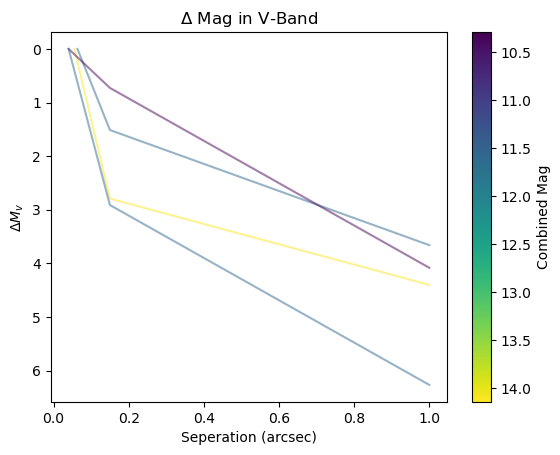

In [22]:
#plotting delta absolute Mag in V-band against seperation in arcsec
fig, ax = plt.subplots()
ax.set_xlabel("Seperation (arcsec)")
ax.set_ylabel("$\Delta M_v$")
ax.set_title("$\Delta$ Mag in V-Band")
ax.invert_yaxis()
for Rho, Dm015, Dm1, C in zip(df[rhomin], df[dm015], df[dm1], df[cMag]): 
    xpoints = [Rho, 0.15, 1.0]
    ypoints = [0.0, Dm015, Dm1]
    color = cmap(norm(C)) 
    ax.plot(xpoints, ypoints, c=color, alpha=0.5)

#colormapping  
colorbar = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(colorbar, ax=ax, label = "Combined Mag")
cbar.ax.invert_yaxis()
plt.show()


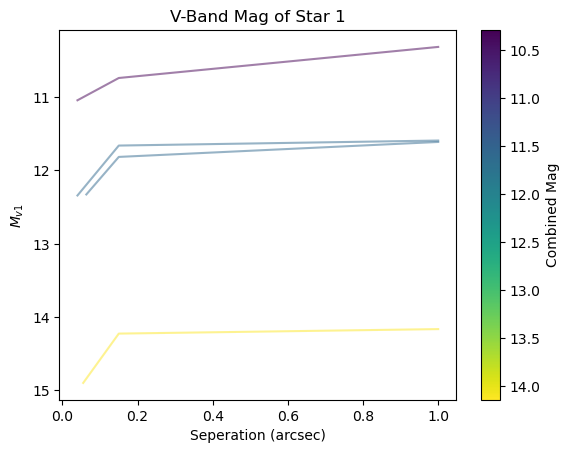

In [24]:
#plotting Mv of star 1 against seperation in arcsec
fig, ax = plt.subplots()
ax.set_xlabel("Seperation (arcsec)")
ax.set_ylabel("$M_{v1}$")
ax.set_title("V-Band Mag of Star 1")
ax.invert_yaxis()
for Rho, dm015, dm1, Mv_min, c in zip(df[rhomin], df['Mv1_015'], df['Mv1_1'], df["Mv1_rhomin"], df[cMag]):
    xpoints = [Rho, 0.15, 1.0]
    ypoints = [Mv_min, dm015, dm1]
    color = cmap(norm(c))
    ax.plot(xpoints, ypoints, c=color, alpha=0.5)
colorbar = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(colorbar, ax=ax, label = "Combined Mag")
cbar.ax.invert_yaxis()
plt.show()

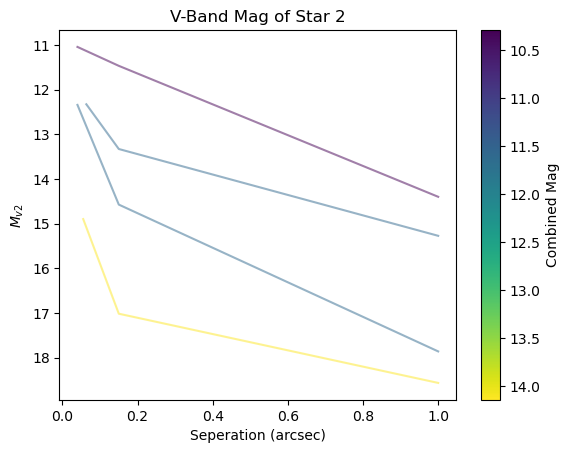

In [25]:
#plotting Mv of star 2 against seperation in arcsec
fig, ax = plt.subplots()
ax.set_xlabel("Seperation (arcsec)")
ax.set_ylabel("$M_{v2}$")
ax.set_title("V-Band Mag of Star 2")
ax.invert_yaxis()
for Rho, dm015, dm1, Mv_min, c in zip(df[rhomin], df['Mv2_015'], df['Mv2_1'], df["Mv2_rhomin"], df[cMag]):
    xpoints = [Rho, 0.15, 1.0]
    ypoints = [Mv_min, dm015, dm1]
    color = cmap(norm(c))
    ax.plot(xpoints, ypoints, c=color, alpha=0.5)
colorbar = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(colorbar, ax=ax, label = "Combined Mag")
cbar.ax.invert_yaxis()
plt.show()

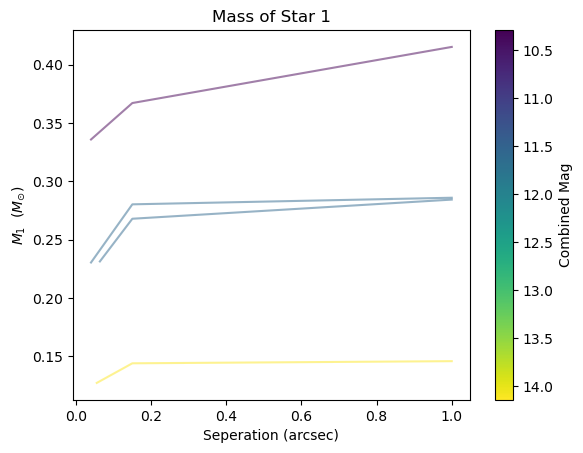

In [26]:
#plotting mass of star 1 against seperation in arcsec
fig, ax = plt.subplots()
ax.set_xlabel("Seperation (arcsec)")
ax.set_ylabel("$M_1$  $(M_{\odot})$")
ax.set_title("Mass of Star 1")
for rho, m015, m1, mRhomin, c in zip(df[rhomin], df['M1_015'], df['M1_1'], df["M1_rhomin"], df[cMag]):
    xpoints = [rho, 0.15, 1.0]
    ypoints = [mRhomin, m015, m1]
    color = cmap(norm(c))
    ax.plot(xpoints, ypoints, c=color, alpha=0.5)
colorbar = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(colorbar, ax=ax, label = "Combined Mag")
cbar.ax.invert_yaxis()
plt.show()

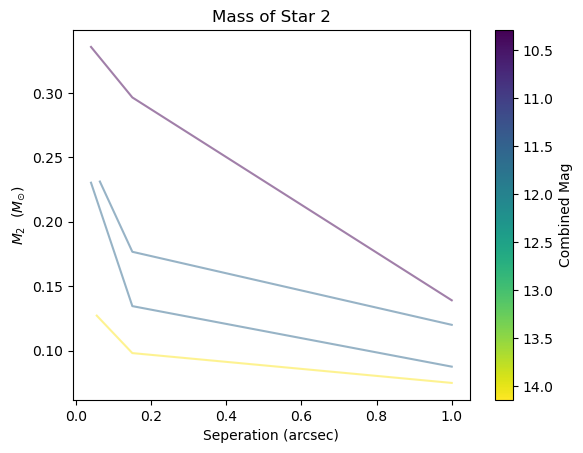

In [27]:
#plotting the mass of star two against seperation in arcsec
fig, ax = plt.subplots()
ax.set_xlabel("Seperation (arcsec)")
ax.set_ylabel("$M_2$  $(M_{\odot})$")
ax.set_title("Mass of Star 2")
for rho, m015, m1, mRhomin, c in zip(df[rhomin], df['M2_015'], df['M2_1'], df["M2_rhomin"], df[cMag]):
    xpoints = [rho, 0.15, 1.0]
    ypoints = [mRhomin, m015, m1]
    color = cmap(norm(c))
    ax.plot(xpoints, ypoints, c=color, alpha=0.5)
colorbar = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(colorbar, ax=ax, label = "Combined Mag")
cbar.ax.invert_yaxis()
plt.show()

In [ ]:
df.head(30)
df.to_csv(final_csv_name, index=False)

,RhoMin,dm015,dm015_err,dm1,dm1_err,Plx,V,I,err_CMag,err_plx,Dist (PC),err_dist,Mv1_015,Mv2_015,Mv1_015_err,Mv2_015_err,Mv1_1,Mv2_1,Mv1_1_err,Mv2_1_err,Mv1_rhomin,Mv2_rhomin,Mv1_rhomin_err,Mv2_rhomin_err,M1_015,M1_015_err,M2_015,M2_015_err,M1_1,M1_1_err,M2_1,M2_1_err,M1_rhomin,M1_rhomin_err,M2_rhomin,M2_rhomin_err
0,0.0553,2.791947,0.137881,4.402850,0.137881,0.103501,14.144723,10.6,0.037288,0.0015,9.661742,0.140024,14.224680,17.016627,0.038551,0.133409,14.163380,18.566230,0.037362,0.140568,14.897298,14.897298,0.037288,0.037288,0.143898,0.029320,0.097983,0.008717,0.145730,0.030229,0.074826,0.017959,0.127080,0.020485,0.127080,0.020485
1,0.0636,1.513307,0.143290,3.661178,0.143290,0.065000,11.574567,9.4,0.053955,0.0015,15.384615,0.355030,11.815215,13.328523,0.061013,0.126850,11.611203,15.272381,0.054164,0.148671,12.327142,12.327142,0.053955,0.053955,0.267817,0.077929,0.176659,0.044323,0.284221,0.083251,0.119934,0.016591,0.231214,0.065404,0.231214,0.065404
2,0.0400,0.727524,0.157009,4.083572,0.157009,0.040000,10.290300,9.9,0.083850,0.0015,25.000000,0.937500,10.738943,11.466467,0.099273,0.133487,10.315263,14.398835,0.083926,0.174856,11.042875,11.042875,0.083850,0.083850,0.367000,0.108066,0.296516,0.087116,0.415100,0.121367,0.138983,0.026860,0.335748,0.099041,0.335748,0.099041
4,0.0400,2.912803,0.139549,6.268851,0.139549,0.085452,11.588611,8.9,0.043046,0.0015,11.702476,0.205422,11.660417,14.573221,0.043962,0.137528,11.591980,17.860831,0.043048,0.145624,12.341186,12.341186,0.043046,0.043046,0.280166,0.081952,0.134471,0.024510,0.285822,0.083764,0.087468,0.012077,0.230298,0.065077,0.230298,0.065077
